In [86]:
from langgraph.graph import StateGraph,START,END
from langchain_groq import ChatGroq
from typing import TypedDict, Annotated
from pydantic import BaseModel, Field
import operator

In [87]:
llm_model = ChatGroq(model="openai/gpt-oss-20b", max_tokens = 1000)
evaluator_llm_model = ChatGroq(model="openai/gpt-oss-120b", max_tokens = 1000)


In [88]:
class LLMScoreModel(BaseModel):
    score: float = Field(description="The score of the blog")
    issues: list[str] = Field(description="The issues found in the blog")

class BlogState(TypedDict):
    topic: str
    blog: str
    evaluation:LLMScoreModel
    iterations: int
    blog_history: Annotated[list[str], operator.add]
    evaluation_history: Annotated[list[LLMScoreModel], operator.add]

In [89]:
def generate_blog(state: BlogState):

    if state["iterations"] == 0:
        prompt = f"""
        Write a blog about {state["topic"]}.
        """
    else:
        prompt = f"""
        Improve the previous blog based on the evaluation.

        Previous blog:
        {state["blog"]}

        Evaluation:
        Score: {state["evaluation"].score}
        Issues:
        {state["evaluation"].issues}

        Rewrite the blog and fix the identified issues.
        """

    blog = llm_model.invoke(prompt)

    return {
        "blog": blog.content,
        "blog_history": [blog.content],
        "iterations": state["iterations"] + 1
    }

def evaluate_blog_accuracy(state: BlogState) -> BlogState:
    print("\n[Accuracy] Started")
    print(f"[Accuracy] Blog length: {len(state['blog'])}")
    
    prompt = f"""
    Evaluate the factual accuracy of the blog below.

    Return ONLY a JSON object.

    Required format:
    {{
        "score": 7,
        "issues": ["issue one", "issue two"]
    }}

    Requirements:
    - score: integer from 1 to 10
    - issues: array of strings
    - maximum 5 issues
    - each issue must be fewer than 20 words
    - mention only factual, misleading, or unsupported claims
    - if no important issues exist, return an empty issues array

    BLOG:
    {state["blog"]}
    """

    accuracy_llm = evaluator_llm_model.with_structured_output(LLMScoreModel, method="json_mode")
    result = accuracy_llm.invoke(prompt)

    print(f"[Accuracy] Result: {result}")
    print("[Accuracy] Finished")

    return {"evaluation": result, "evaluation_history": [result]}


def check_evaluation(state: BlogState): 
    if(state['iterations'] > 3 or state['evaluation'].score > 5): 
        return "approved"
    else: 
        return "not_approved"

def final_blog(state:BlogState):
    return {}


In [90]:
graph = StateGraph(BlogState)

graph.add_node("generate_blog", generate_blog)
graph.add_node("evaluate_blog_accuracy", evaluate_blog_accuracy)
graph.add_node("final_blog", final_blog)

graph.add_edge(START, "generate_blog")
graph.add_edge("generate_blog", "evaluate_blog_accuracy")
graph.add_conditional_edges("evaluate_blog_accuracy", check_evaluation, {"approved": "final_blog", "not_approved": "generate_blog"})

graph.add_edge("final_blog", END)

workflow = graph.compile()

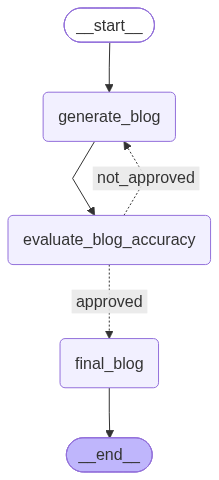

In [91]:
from IPython.display import display, Image
display(Image(workflow.get_graph().draw_mermaid_png()))

In [92]:
initial_state = {
    "topic": "The Future of Autonomous AI Agents: Architecture, Memory, Tool Use, Multi-Agent Systems, Security, Reliability, Evaluation, Cost, and Real-World Deployment",
    "blog": "",
    "evaluation": LLMScoreModel(score=0, issues=[]),
    "iterations": 0,
    "blog_history": [],
    "evaluation_history": [],
}

result = workflow.invoke(initial_state)


[Accuracy] Started
[Accuracy] Blog length: 2959
[Accuracy] Result: score=6.0 issues=['LLMs did not exist in 2015‑2018; early agents were not LLM‑based.', 'Claim that autonomous AI agents are the backbone of next‑gen software is unsupported.', 'Statement that multi‑agent systems inherently provide redundancy is misleading; redundancy requires explicit design.', 'Implying a universal service‑oriented architecture for all agents oversimplifies diverse implementations.']
[Accuracy] Finished


In [93]:
print("Iterations:", result["iterations"])
print("Blog history:", len(result["blog_history"]))
print("Evaluation history:", len(result["evaluation_history"]))

print("Evaluation History:", result["evaluation_history"])
# print("Blog History:", result["blog_history"])

# print("Final Blog:", result["blog"])

Iterations: 1
Blog history: 1
Evaluation history: 1
Evaluation History: [LLMScoreModel(score=6.0, issues=['LLMs did not exist in 2015‑2018; early agents were not LLM‑based.', 'Claim that autonomous AI agents are the backbone of next‑gen software is unsupported.', 'Statement that multi‑agent systems inherently provide redundancy is misleading; redundancy requires explicit design.', 'Implying a universal service‑oriented architecture for all agents oversimplifies diverse implementations.'])]
